# Test a trained SEM PnP-Flow model

This notebook evaluates a trained OT flow-matching prior on held-out SEM patches. It creates a known synthetic corruption, applies the same PnP-Flow update used by `main.py`, and compares the corrupted input and reconstruction against the clean test patch.

The test data are normalized to `[-1, 1]`; plots and PSNR calculations below use that range.

In [1]:
from pathlib import Path
import os

# Run from the PnP-Flow repository, regardless of the notebook's working directory.
repo_root = Path.cwd().resolve()
if not (repo_root / 'pnpflow').is_dir():
    candidate = repo_root.parent
    if (candidate / 'pnpflow').is_dir():
        repo_root = candidate
    else:
        raise RuntimeError('Open this notebook from the PnP-Flow repository or its notebooks/ directory.')
os.chdir(repo_root)

# Set both values to inspect another trained SEM model.
DATASET_NAME = 'sem_nffa'
RUN_NAME = '20260712_150348_sem_nffa_ot'
CHECKPOINT_NAME = 'model_final.pt'  # e.g. 'model_50.pt' for an intermediate checkpoint
checkpoint_path = repo_root / 'model' / DATASET_NAME / 'ot' / RUN_NAME / CHECKPOINT_NAME
dataset_root = repo_root / 'data' / DATASET_NAME

assert checkpoint_path.is_file(), f'Checkpoint not found: {checkpoint_path}'
assert (dataset_root / 'test').is_dir(), f"Test patches not found: {dataset_root / 'test'}"
print(f'Repository: {repo_root}')
print(f'Checkpoint: {checkpoint_path}')
print(f"Test patches: {dataset_root / 'test'}")

Repository: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow
Checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa/ot/20260712_150348_sem_nffa_ot/model_final.pt
Test patches: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/data/sem_nffa/test


In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from pnpflow.dataloaders import HAADFNpyDataset
from pnpflow.utils import define_model
from pnpflow.degradations import FixedMaskInpainting

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)
print(f'Device: {device}')

class ModelArgs:
    model = 'ot'
    num_channels = 1
    dim_image = 128

model, _ = define_model(ModelArgs())
state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.to(device).eval()

# Optional multi-GPU inference. The model remains on cuda:0 and DataParallel
# splits each tile batch across the selected visible GPUs.
USE_MULTI_GPU = True
GPU_IDS = list(range(torch.cuda.device_count()))
if USE_MULTI_GPU and device.type == 'cuda' and len(GPU_IDS) > 1:
    model = torch.nn.DataParallel(model, device_ids=GPU_IDS, output_device=GPU_IDS[0])
    print(f'Multi-GPU inference enabled on {len(GPU_IDS)} GPUs: {GPU_IDS}')
else:
    print(f'Single-device inference on {device}')

test_dataset = HAADFNpyDataset(dataset_root / 'test')
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False)
clean, _ = next(iter(test_loader))
clean = clean.to(device)
print(f'Loaded {len(test_dataset)} held-out patches with shape {tuple(clean.shape)}')

/data2/marci/bselvaku/conda/envs/torchlearn/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Multi-GPU inference enabled on 4 GPUs: [0, 1, 2, 3]
Loaded 3236 held-out patches with shape (4, 1, 128, 128)


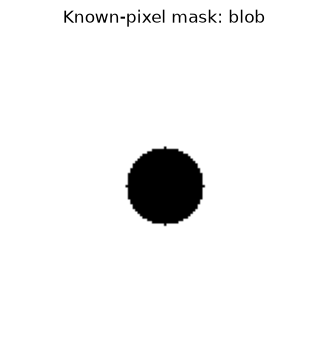

In [3]:
def make_known_mask(kind='blob', dim=128, radius=16, line_width=8, missing_fraction=0.15, seed=0):
    """Return 1 for observed pixels and 0 for pixels to reconstruct."""
    generator = torch.Generator(device='cpu').manual_seed(seed)
    known = torch.ones(1, 1, dim, dim)
    if kind == 'blob':
        yy, xx = torch.meshgrid(torch.arange(dim), torch.arange(dim), indexing='ij')
        missing = (yy - dim // 2).square() + (xx - dim // 2).square() <= radius ** 2
        known[:, :, missing] = 0
    elif kind == 'line':
        half = max(1, line_width // 2)
        known[:, :, dim // 2 - half:dim // 2 + half, :] = 0
    elif kind == 'random':
        known = (torch.rand((1, 1, dim, dim), generator=generator) > missing_fraction).float()
    else:
        raise ValueError("kind must be 'blob', 'line', or 'random'")
    return known

MASK_KIND = 'blob'       # 'blob', 'line', or 'random'
NOISE_STD = 0.01        # Same Gaussian level used by the microscopy inpainting path in main.py
STEPS_PNP = 100         # Same default as config/method_config/pnp_flow.yaml
NUM_SAMPLES = 5         # Monte-Carlo prior estimates per PnP step
LR_PNP = 1.0            # The solver scales this by NOISE_STD**2
ALPHA = 1.0

known_mask = make_known_mask(MASK_KIND, dim=clean.shape[-1]).to(device)
degradation = FixedMaskInpainting(known_mask)
observed = degradation.H(clean)
observed = observed + known_mask * torch.randn_like(observed) * NOISE_STD

plt.figure(figsize=(4, 4))
plt.imshow(known_mask[0, 0].cpu(), cmap='gray', vmin=0, vmax=1)
plt.title(f'Known-pixel mask: {MASK_KIND}')
plt.axis('off');
plt.show()

In [4]:
@torch.no_grad()
def pnp_flow_inpaint(model, observed, degradation, noise_std, steps=100, num_samples=5, lr_pnp=1.0, alpha=1.0):
    """PnP-Flow update matching PNP_FLOW.solve_ip for Gaussian inpainting."""
    x = degradation.H_adj(observed).clone()
    known = degradation.H_adj(torch.ones_like(observed)).to(observed.device)
    lr = noise_std ** 2 * lr_pnp
    delta = 1.0 / steps

    for iteration in range(steps):
        t = torch.full((len(x),), delta * iteration, device=x.device)
        lr_t = lr * (1.0 - t).pow(alpha).view(-1, 1, 1, 1)
        z = x - lr_t * degradation.H_adj(degradation.H(x) - observed) / (noise_std ** 2)

        x_new = torch.zeros_like(x)
        for _ in range(num_samples):
            z_tilde = t.view(-1, 1, 1, 1) * z + (1.0 - t).view(-1, 1, 1, 1) * torch.randn_like(z)
            velocity = model(z_tilde, t)
            x_new += z_tilde + (1.0 - t).view(-1, 1, 1, 1) * velocity
        x_new /= num_samples
        x = known * observed + (1.0 - known) * x_new

    return x.clamp(-1, 1)

reconstruction = pnp_flow_inpaint(
    model, observed, degradation, NOISE_STD,
    steps=STEPS_PNP, num_samples=NUM_SAMPLES, lr_pnp=LR_PNP, alpha=ALPHA,
)
print('Reconstruction complete.')

Reconstruction complete.


Corrupted full-patch PSNR: 19.69 dB
Reconstruction full-patch PSNR: 43.28 dB
Corrupted missing-region PSNR: 6.57 dB
Reconstruction missing-region PSNR: 33.59 dB
Maximum known-pixel consistency error: 4.022e-02


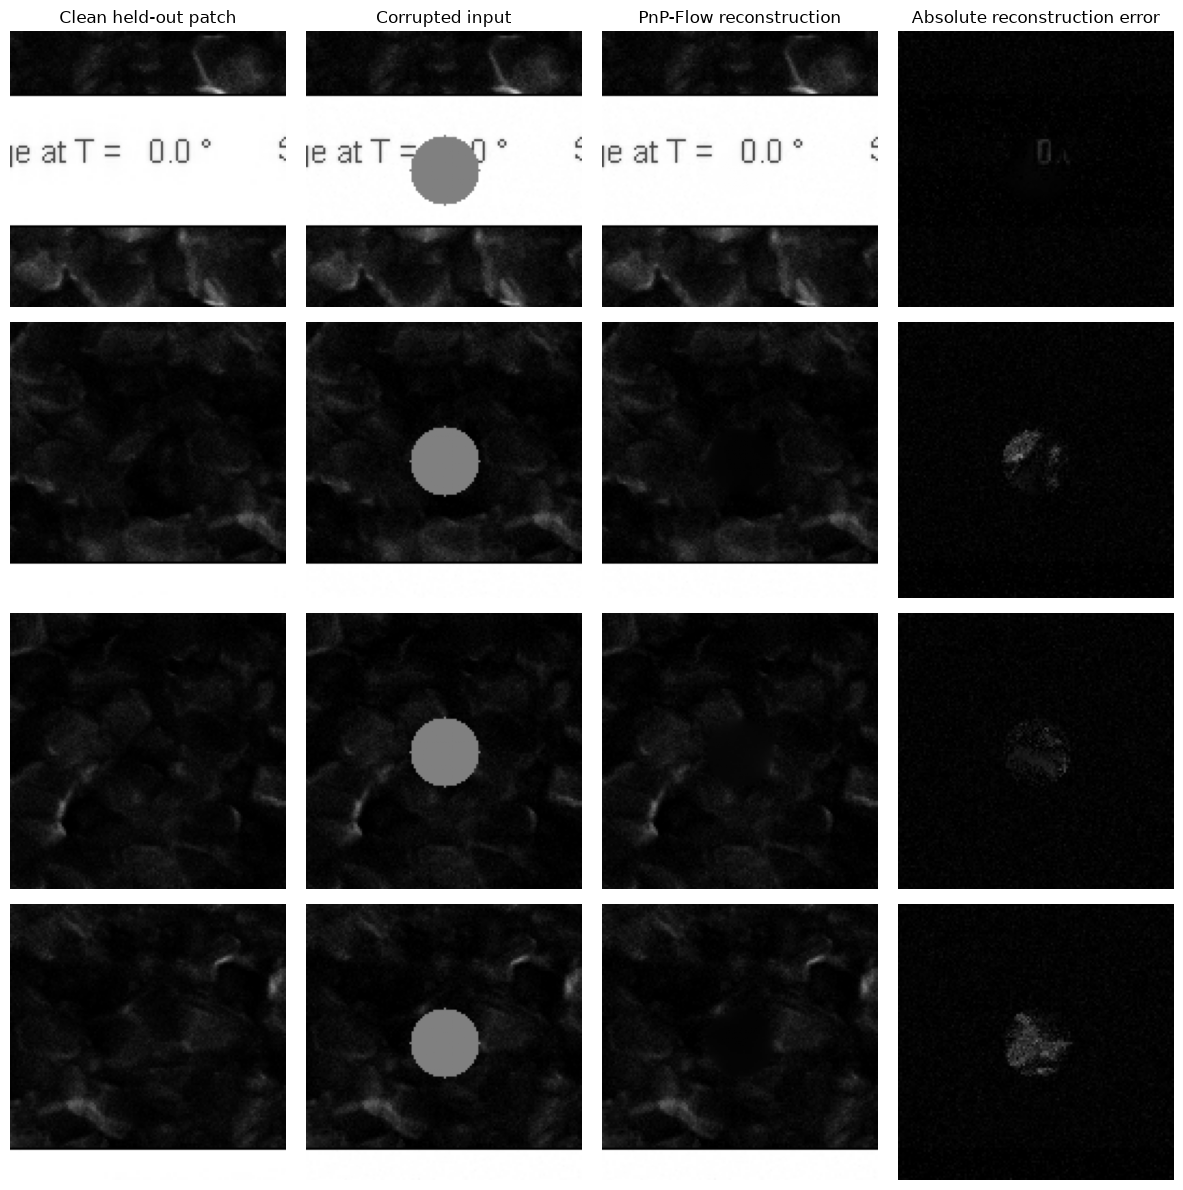

In [5]:
def psnr(reference, estimate, mask=None):
    error = (reference - estimate).square()
    if mask is not None:
        mask = mask.expand_as(error)
        mse = (error * mask).sum(dim=(1, 2, 3)) / mask.sum(dim=(1, 2, 3)).clamp_min(1)
    else:
        mse = error.mean(dim=(1, 2, 3))
    return 10 * torch.log10(torch.tensor(4.0, device=reference.device) / mse.clamp_min(1e-12))

missing_mask = 1.0 - known_mask
metrics = {
    'Corrupted full-patch PSNR': psnr(clean, observed),
    'Reconstruction full-patch PSNR': psnr(clean, reconstruction),
    'Corrupted missing-region PSNR': psnr(clean, observed, missing_mask),
    'Reconstruction missing-region PSNR': psnr(clean, reconstruction, missing_mask),
}
for name, values in metrics.items():
    print(f'{name}: {values.mean().item():.2f} dB')

known_error = ((reconstruction - observed).abs() * known_mask).max().item()
print(f'Maximum known-pixel consistency error: {known_error:.3e}')

images = [clean, observed, reconstruction, (clean - reconstruction).abs()]
titles = ['Clean held-out patch', 'Corrupted input', 'PnP-Flow reconstruction', 'Absolute reconstruction error']
fig, axes = plt.subplots(len(clean), 4, figsize=(12, 3 * len(clean)), squeeze=False)
for row in range(len(clean)):
    for column, (image, title) in enumerate(zip(images, titles)):
        vmin, vmax = (0, 0.5) if column == 3 else (-1, 1)
        axes[row, column].imshow(image[row, 0].detach().cpu(), cmap='gray', vmin=vmin, vmax=vmax)
        axes[row, column].set_title(title if row == 0 else '')
        axes[row, column].axis('off')
plt.tight_layout()
plt.show()

## Inpaint a raw SEM image with a synthetic square mask

This workflow loads the raw source image for a held-out `sem_nffa` patch, constructs a square missing-pixel mask, and runs the current PnP-Flow model only on 128 x 128 tiles intersecting that square. The original raw image is retained as the synthetic-test reference.

Set `RAW_SEM_IMAGE` directly to inspect another raw JPEG. The model input is converted to grayscale and normalized with the same per-image 1st/99th-percentile procedure used during SEM patch preparation.

In [18]:
from PIL import Image
import numpy as np

# This held-out source is compatible with the sem_nffa test set selected above.
# Set RAW_SEM_IMAGE directly to reconstruct a different JPEG from RAW_SEM_ROOT.
RAW_SEM_ROOT = Path('/data2/marci/bselvaku/nffa_sem/raw_images')
RAW_SEM_IMAGE = RAW_SEM_ROOT / 'Films_Coated_Surface/L3_18eb5526ada181c27f7f6fac74b280d9.jpg'

# The synthetic external mask is a square centered in the original image.
# Match the working radius-16 circular test: pi * 16**2 ~= 804 pixels,
# while a 28 x 28 square contains 784 missing pixels.
SQUARE_SIZE = 16
TILE_SIZE = 128
TILE_STRIDE = 64
INFERENCE_BATCH_SIZE = 1024
RAW_IMAGE_SIGMA = 0.01

with Image.open(RAW_SEM_IMAGE) as image:
    raw_sem = np.asarray(image.convert('L'), dtype=np.float32)
if raw_sem.ndim != 2 or not np.isfinite(raw_sem).all():
    raise ValueError(f'Expected a finite 2D grayscale image: {RAW_SEM_IMAGE}')

height, width = raw_sem.shape
if SQUARE_SIZE > min(height, width):
    raise ValueError(f'SQUARE_SIZE={SQUARE_SIZE} is larger than image shape {raw_sem.shape}')
square_top = (height - SQUARE_SIZE) // 2
square_left = (width - SQUARE_SIZE) // 2
missing = np.zeros(raw_sem.shape, dtype=bool)
missing[square_top:square_top + SQUARE_SIZE, square_left:square_left + SQUARE_SIZE] = True

# Match scripts/prepare_sem_patches.py: grayscale, 1st/99th-percentile clip, then [-1, 1].
low, high = np.percentile(raw_sem, (1, 99))
if not high > low:
    raise ValueError('Image has no usable intensity range for percentile normalization.')
raw_sem_norm = 2 * np.clip((raw_sem - low) / (high - low), 0, 1) - 1
observed_raw = raw_sem.copy()
observed_raw[missing] = 0
print(f'Raw image: {RAW_SEM_IMAGE}')
print(f'X size (width): {width} pixels; Y size (height): {height} pixels')
print(f'Synthetic missing square: x={square_left}:{square_left + SQUARE_SIZE}, y={square_top}:{square_top + SQUARE_SIZE}')
print(f'Normalization range: [{low:.5g}, {high:.5g}]')

Raw image: /data2/marci/bselvaku/nffa_sem/raw_images/Films_Coated_Surface/L3_18eb5526ada181c27f7f6fac74b280d9.jpg
X size (width): 1024 pixels; Y size (height): 768 pixels
Synthetic missing square: x=504:520, y=376:392
Normalization range: [32, 255]


Centered model tile: rows 320:448, columns 448:576; missing fraction 1.56%
Reconstructed normalized range inside mask: [-0.4586, 0.4341], mean=0.0833, clamped-at--1=0.00%
Maximum change outside mask: 0.000e+00


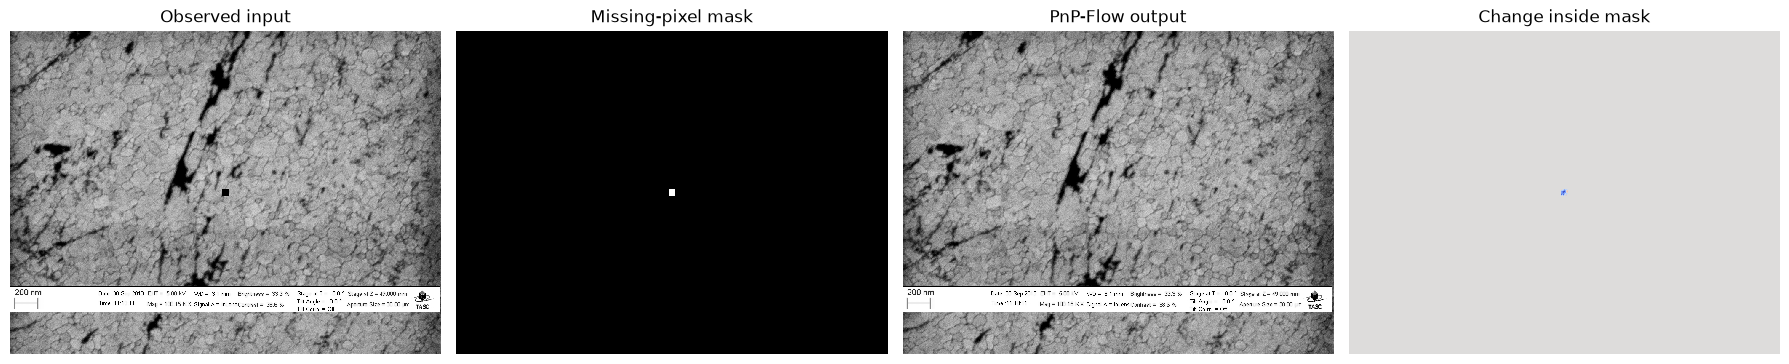

In [19]:
def tile_starts(length, tile_size, stride):
    if length < tile_size:
        return [0]
    starts = list(range(0, length - tile_size + 1, stride))
    last = length - tile_size
    if starts[-1] != last:
        starts.append(last)
    return starts

def inpaint_masked_image(corrupted_norm, missing, model):
    height, width = corrupted_norm.shape
    padded_height = max(height, TILE_SIZE)
    padded_width = max(width, TILE_SIZE)
    pad = ((0, padded_height - height), (0, padded_width - width))
    pad_mode = 'reflect' if min(height, width) > 1 else 'edge'
    image_pad = np.pad(corrupted_norm, pad, mode=pad_mode)
    missing_pad = np.pad(missing, pad, mode='constant', constant_values=False)

    locations = [
        (top, left)
        for top in tile_starts(padded_height, TILE_SIZE, TILE_STRIDE)
        for left in tile_starts(padded_width, TILE_SIZE, TILE_STRIDE)
        if missing_pad[top:top + TILE_SIZE, left:left + TILE_SIZE].any()
    ]
    if not locations:
        return corrupted_norm.copy()

    reconstruction_sum = np.zeros_like(image_pad, dtype=np.float32)
    reconstruction_count = np.zeros_like(image_pad, dtype=np.float32)
    for offset in range(0, len(locations), INFERENCE_BATCH_SIZE):
        batch_locations = locations[offset:offset + INFERENCE_BATCH_SIZE]
        image_tiles = np.stack([image_pad[top:top + TILE_SIZE, left:left + TILE_SIZE] for top, left in batch_locations])
        missing_tiles = np.stack([missing_pad[top:top + TILE_SIZE, left:left + TILE_SIZE] for top, left in batch_locations])
        tile_tensor = torch.from_numpy(image_tiles[:, None]).float().to(device)
        known_tensor = torch.from_numpy((~missing_tiles)[:, None].astype(np.float32)).to(device)
        degradation = FixedMaskInpainting(known_tensor)
        restored_tiles = pnp_flow_inpaint(
            model, degradation.H(tile_tensor), degradation, RAW_IMAGE_SIGMA,
            steps=STEPS_PNP, num_samples=NUM_SAMPLES, lr_pnp=LR_PNP, alpha=ALPHA,
        ).cpu().numpy()[:, 0]

        for restored_tile, missing_tile, (top, left) in zip(restored_tiles, missing_tiles, batch_locations):
            missing_float = missing_tile.astype(np.float32)
            target = np.s_[top:top + TILE_SIZE, left:left + TILE_SIZE]
            reconstruction_sum[target] += restored_tile * missing_float
            reconstruction_count[target] += missing_float

    restored_pad = image_pad.copy()
    reconstructed = reconstruction_count > 0
    restored_pad[reconstructed] = reconstruction_sum[reconstructed] / reconstruction_count[reconstructed]
    return restored_pad[:height, :width]

def inpaint_single_centered_square(image_norm, missing_mask, model):
    """Inpaint one square using one centered 128 x 128 model input.

    This matches the direct patch inference used by the working circular-mask
    benchmark and avoids averaging independent stochastic tile reconstructions.
    """
    missing_rows, missing_cols = np.where(missing_mask)
    if len(missing_rows) == 0:
        return image_norm.copy()

    box_height = int(missing_rows.max() - missing_rows.min() + 1)
    box_width = int(missing_cols.max() - missing_cols.min() + 1)
    if box_height > TILE_SIZE or box_width > TILE_SIZE:
        raise ValueError(
            f'Missing square is {box_width} x {box_height}, but the model input is '
            f'{TILE_SIZE} x {TILE_SIZE}. Use a larger-context model for this mask.'
        )

    image_height, image_width = image_norm.shape
    if image_height < TILE_SIZE or image_width < TILE_SIZE:
        raise ValueError(f'Image shape {image_norm.shape} is smaller than the model input.')

    center_y = int((missing_rows.min() + missing_rows.max() + 1) // 2)
    center_x = int((missing_cols.min() + missing_cols.max() + 1) // 2)
    tile_top = int(np.clip(center_y - TILE_SIZE // 2, 0, image_height - TILE_SIZE))
    tile_left = int(np.clip(center_x - TILE_SIZE // 2, 0, image_width - TILE_SIZE))
    tile_target = np.s_[tile_top:tile_top + TILE_SIZE, tile_left:tile_left + TILE_SIZE]

    image_tile = image_norm[tile_target]
    missing_tile = missing_mask[tile_target]
    if missing_tile.all():
        raise ValueError(
            'The missing square covers the entire 128 x 128 model input, leaving no observed '
            'context. Reduce SQUARE_SIZE below TILE_SIZE or use a larger-context model.'
        )

    tile_tensor = torch.from_numpy(image_tile[None, None]).float().to(device)
    known_tensor = torch.from_numpy((~missing_tile)[None, None].astype(np.float32)).to(device)
    degradation = FixedMaskInpainting(known_tensor)
    restored_tile = pnp_flow_inpaint(
        model, degradation.H(tile_tensor), degradation, RAW_IMAGE_SIGMA,
        steps=STEPS_PNP, num_samples=NUM_SAMPLES, lr_pnp=LR_PNP, alpha=ALPHA,
    ).cpu().numpy()[0, 0]

    output = image_norm.copy()
    output_view = output[tile_target]
    output_view[missing_tile] = restored_tile[missing_tile]
    print(
        f'Centered model tile: rows {tile_top}:{tile_top + TILE_SIZE}, '
        f'columns {tile_left}:{tile_left + TILE_SIZE}; missing fraction '
        f'{missing_tile.mean():.2%}'
    )
    return output

restored_norm = inpaint_single_centered_square(raw_sem_norm, missing, model)
# This assignment is the final data-consistency guard: known input pixels cannot change.
restored_norm[~missing] = raw_sem_norm[~missing]
restored_raw = raw_sem.copy()
restored_raw[missing] = ((restored_norm[missing] + 1) * 0.5 * (high - low) + low)

inside = restored_norm[missing]
print(
    f'Reconstructed normalized range inside mask: [{inside.min():.4f}, {inside.max():.4f}], '
    f'mean={inside.mean():.4f}, clamped-at--1={(inside <= -0.999).mean():.2%}'
)

known_change = np.abs(restored_raw[~missing] - raw_sem[~missing]).max()
print(f'Maximum change outside mask: {known_change:.3e}')

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
views = [observed_raw, missing, restored_raw, np.where(missing, restored_raw - raw_sem, 0)]
titles = ['Observed input', 'Missing-pixel mask', 'PnP-Flow output', 'Change inside mask']
for axis, view, title in zip(axes, views, titles):
    if title == 'Missing-pixel mask':
        axis.imshow(view, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    elif title == 'Change inside mask':
        max_change = max(float(np.abs(view).max()), 1e-6)
        axis.imshow(view, cmap='coolwarm', vmin=-max_change, vmax=max_change, interpolation='nearest')
    else:
        axis.imshow(view, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

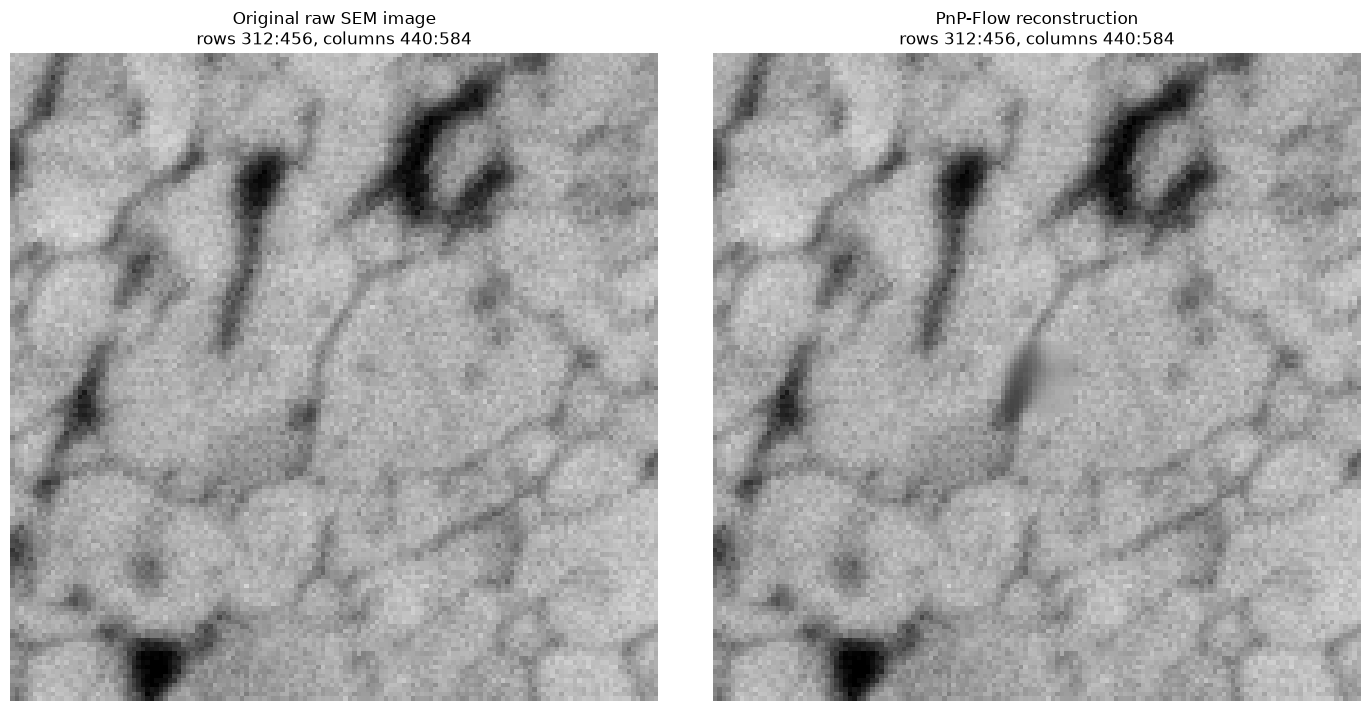

: 

In [ ]:
# Zoomed synthetic-test comparison: the original raw image is known in this case.
ZOOM_MARGIN = 64
zoom_top = max(0, square_top - ZOOM_MARGIN)
zoom_bottom = min(height, square_top + SQUARE_SIZE + ZOOM_MARGIN)
zoom_left = max(0, square_left - ZOOM_MARGIN)
zoom_right = min(width, square_left + SQUARE_SIZE + ZOOM_MARGIN)
zoom = np.s_[zoom_top:zoom_bottom, zoom_left:zoom_right]

raw_zoom = raw_sem[zoom]
restored_zoom = restored_raw[zoom]
fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
for axis, image, title in zip(
    axes,
    (raw_zoom, restored_zoom),
    ('Original raw SEM image', 'PnP-Flow reconstruction'),
):
    axis.imshow(image, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
    axis.set_title(f'{title}\nrows {zoom_top}:{zoom_bottom}, columns {zoom_left}:{zoom_right}')
    axis.axis('off')
plt.show()


## Interpretation

Compare **missing-region PSNR**, not only full-patch PSNR: the PnP solver deliberately copies known pixels from the observation, so full-patch scores can hide failure inside the masked region. The clean patch is only available here because the corruption is synthetic. For real beam-damaged images, use the same inference cell with a mask derived from the damage map, but do not report PSNR without a clean reference.

To run the repository's batch evaluator instead, use a unique `eval_run_name` and this completed model run:

```bash
python main.py --opts dataset sem_nffa model ot model_run 20260712_150348_sem_nffa train False eval True eval_split test problem haadf_blob_inpainting method pnp_flow batch_size_ip 4 max_batch 4 eval_run_name sem_100ep_blob_test
```

The notebook visualization is preferred for inspection because the current generic result saver was written for images in `[0, 1]`, whereas SEM patches are stored in `[-1, 1]`.